# 📊 EDA Pipeline — Res16 (SemEval 2016 Task 5)
**Aspect-Based Sentiment Analysis | Restaurant Reviews**

---
**Mục tiêu notebook này:**
1. Đọc XML gốc, gộp train + test → flat DataFrame (mỗi hàng = 1 aspect opinion)
2. Phân tích không gian nhãn (Label Space Analysis)
3. Trực quan hoá phân bố (Distribution Visualization)
4. Trích xuất ví dụ & minh hoạ cơ chế Mapping


In [27]:
# ── Cell 1: Import thư viện ──────────────────────────────────────────────────
import re
import random
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display

# Style chung
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({'figure.dpi': 130, 'font.size': 11})
POLARITY_COLORS = {'positive': '#2ecc71', 'negative': '#e74c3c', 'neutral': '#f39c12'}

print('✅ Libraries loaded successfully.')

✅ Libraries loaded successfully.


---
## 🔀 Bước 0 — Đọc XML & gộp Train + Test → Flat DataFrame

File gốc SemEval-2016 là **XML lồng nhau** (`Review → sentence → Opinion`): một review có nhiều câu, mỗi câu có thể có nhiều opinion.
Ta *làm phẳng* về dạng 1 hàng = 1 opinion (cặp câu–khía cạnh) bằng `parse_xml` trong `src/absa_common.py`
(cùng hàm mà các notebook huấn luyện dùng, nên số liệu EDA và số liệu huấn luyện luôn khớp nhau).

> Bản cũ của notebook đọc `restaurants_*_sb1.csv` (dạng wide, lấy từ Kaggle) — file này **không có** trong `data/` của repo, nên không chạy lại được. Bản này đọc thẳng XML.

In [28]:
# ── Cell 2: Đọc dữ liệu từ XML gốc ──────────────────────────────────────────
import sys
sys.path.append('../src')
from absa_common import parse_xml

df_train_raw = parse_xml('../data/restaurants_train_sb1.xml')
df_test_raw  = parse_xml('../data/restaurants_test_sb1.xml')

print(f'Train: {len(df_train_raw):,} opinions · {df_train_raw.rid.nunique()} reviews · {df_train_raw.sid.nunique():,} câu có nhãn')
print(f'Test : {len(df_test_raw):,} opinions · {df_test_raw.rid.nunique()} reviews · {df_test_raw.sid.nunique():,} câu có nhãn')

Train: 2,507 opinions · 349 reviews · 1,708 câu có nhãn
Test : 859 opinions · 90 reviews · 587 câu có nhãn


In [29]:
# ── Cell 3: Chuẩn hoá thành flat DataFrame ─────────────────────────────────
def to_flat(raw, split_label):
    out = raw.rename(columns={'sentence': 'text'}).copy()
    out['split'] = split_label
    out['text_len'] = out['text'].str.len()
    return out[['split', 'rid', 'sid', 'text', 'category', 'polarity', 'target', 'text_len']]

df_train = to_flat(df_train_raw, 'train')
df_test  = to_flat(df_test_raw,  'test')
df       = pd.concat([df_train, df_test], ignore_index=True)

print(f'\n📦 Kết quả sau khi flatten & combine:')
print(f'   Train opinions : {len(df_train):,}')
print(f'   Test  opinions : {len(df_test):,}')
print(f'   TOTAL opinions : {len(df):,}')


📦 Kết quả sau khi flatten & combine:
   Train opinions : 2,507
   Test  opinions : 859
   TOTAL opinions : 3,366


In [30]:
# ── Cell 4: Xem trước flat DataFrame ────────────────────────────────────────
print('📋 Schema & sample data:')
print(f'Columns: {df.columns.tolist()}')
print(f'Shape  : {df.shape}\n')
display(df.sample(5, random_state=42).reset_index(drop=True))

📋 Schema & sample data:
Columns: ['split', 'rid', 'sid', 'text', 'category', 'polarity', 'target', 'text_len']
Shape  : (3366, 8)



,split,rid,sid,text,category,polarity,target,text_len
0,train,444818,444818:1,"The atmosphere is unheralded, the service impe...",SERVICE#GENERAL,positive,service,78
1,train,FF#3,FF#3:6,I took one look at the chicken and I was appal...,FOOD#STYLE_OPTIONS,negative,chicken,50
2,train,1623276,1623276:0,Patroon features a nice cigar bar and has grea...,AMBIENCE#GENERAL,positive,cigar bar,54
3,test,en_India'sGrill_477960694,en_India'sGrill_477960694:6,I appreciate their delivery too.,SERVICE#GENERAL,positive,delivery,32
4,train,1153034,1153034:4,I will be back!,RESTAURANT#GENERAL,positive,NULL,15


---
## 🏷️ Bước 1 — Phân tích Không gian Nhãn (Label Space Analysis)

Res16 sử dụng schema `Entity#Attribute` cho category và 3 polarity class.  
Mục tiêu: đếm chính xác số lượng nhãn, hiểu cấu trúc tổ hợp của chúng.

In [31]:
# ── Cell 5: Tách Entity và Attribute từ category ─────────────────────────────
df[['entity', 'attribute']] = df['category'].str.split('#', expand=True)

unique_categories  = sorted(df['category'].unique())
unique_entities    = sorted(df['entity'].unique())
unique_attributes  = sorted(df['attribute'].unique())
unique_polarities  = sorted(df['polarity'].unique())

# Tổ hợp nhãn thực sự xuất hiện trong dữ liệu
label_combos = df.groupby(['category', 'polarity']).size().reset_index(name='count')

print('=' * 55)
print('           LABEL SPACE SUMMARY — RES16')
print('=' * 55)
print(f'  Unique Entities (E)          : {len(unique_entities)}')
print(f'  Unique Attributes (A)        : {len(unique_attributes)}')
print(f'  Unique Categories (E#A)      : {len(unique_categories)}')
print(f'  Unique Polarities (P)        : {len(unique_polarities)}')
print(f'  Max theoretical labels E#AxP : {len(unique_categories)*len(unique_polarities)}')
print(f'  Actual label combos observed : {len(label_combos)}')
print('=' * 55)
print(f'\n  Entities  : {unique_entities}')
print(f'  Attributes: {unique_attributes}')
print(f'  Polarities: {unique_polarities}')

           LABEL SPACE SUMMARY — RES16
  Unique Entities (E)          : 6
  Unique Attributes (A)        : 5
  Unique Categories (E#A)      : 12
  Unique Polarities (P)        : 3
  Max theoretical labels E#AxP : 36
  Actual label combos observed : 34

  Entities  : ['AMBIENCE', 'DRINKS', 'FOOD', 'LOCATION', 'RESTAURANT', 'SERVICE']
  Attributes: ['GENERAL', 'MISCELLANEOUS', 'PRICES', 'QUALITY', 'STYLE_OPTIONS']
  Polarities: ['negative', 'neutral', 'positive']


In [32]:
# ── Cell 6: Bảng tần suất nhãn đầy đủ ──────────────────────────────────────
label_freq = (
    df.groupby(['category', 'polarity'])
      .size()
      .unstack(fill_value=0)
      .reindex(columns=['positive', 'negative', 'neutral'], fill_value=0)
)
label_freq['TOTAL'] = label_freq.sum(axis=1)
label_freq = label_freq.sort_values('TOTAL', ascending=False)

print('📊 Tần suất nhãn theo Category × Polarity (combined train+test):')
display(label_freq.style
        .background_gradient(cmap='YlOrRd', subset=['TOTAL'])
        .format('{:,}'))

📊 Tần suất nhãn theo Category × Polarity (combined train+test):


polarity,positive,negative,neutral,TOTAL
category,,,,
FOOD#QUALITY,886,235,41,"1,162"
SERVICE#GENERAL,283,302,19,604
RESTAURANT#GENERAL,420,135,9,564
AMBIENCE#GENERAL,258,44,19,321
FOOD#STYLE_OPTIONS,114,60,18,192
RESTAURANT#MISCELLANEOUS,74,40,17,131
FOOD#PRICES,47,62,4,113
RESTAURANT#PRICES,40,53,8,101
DRINKS#QUALITY,61,6,2,69


In [33]:
# ── Cell 7: Train vs Test split so sánh ─────────────────────────────────────
split_stats = df.groupby('split').agg(
    total_opinions=('text', 'count'),
    unique_texts=('text', 'nunique'),
    unique_categories=('category', 'nunique'),
    avg_text_len=('text_len', 'mean')
).round(1)

print('📋 Train / Test split summary:')
display(split_stats)

📋 Train / Test split summary:


,total_opinions,unique_texts,unique_categories,avg_text_len
split,,,,
test,859,586,12,83.6
train,2507,1703,12,77.6


---
## 📈 Bước 2 — Trực quan hoá Phân bố (Distribution Visualization)

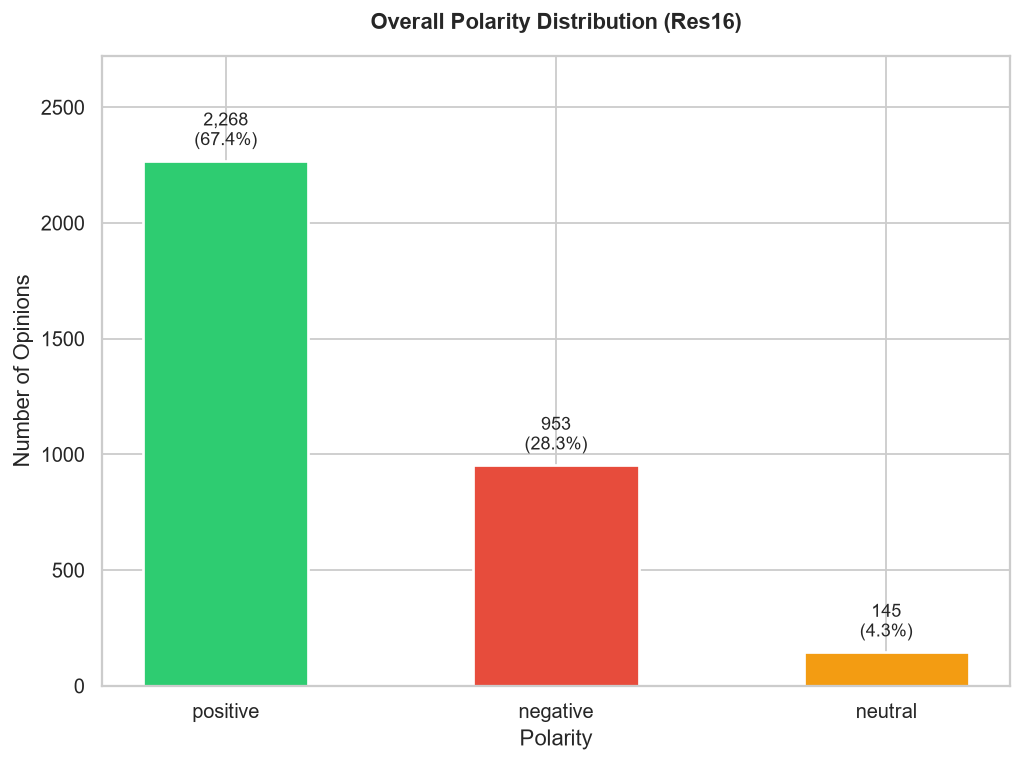

⚠️  Class imbalance ratio (positive:negative:neutral) = 2268:953:145


In [34]:
fig, ax = plt.subplots(figsize=(8, 6))

pol_counts = df['polarity'].value_counts().reindex(['positive', 'negative', 'neutral'])

# Bar chart
bars = ax.bar(
    pol_counts.index,
    pol_counts.values,
    color=[POLARITY_COLORS[p] for p in pol_counts.index],
    edgecolor='white', linewidth=1.5, width=0.5
)

ax.set_title('Overall Polarity Distribution (Res16)', fontweight='bold', pad=15)
ax.set_ylabel('Number of Opinions')
ax.set_xlabel('Polarity')

# Thêm nhãn số liệu phía trên cột
for bar, val in zip(bars, pol_counts.values):
    pct = val / pol_counts.sum() * 100
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + (pol_counts.max() * 0.02),
            f'{val:,}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=10)

ax.set_ylim(0, pol_counts.max() * 1.2)
plt.tight_layout()
plt.show()

print(f'⚠️  Class imbalance ratio (positive:negative:neutral) = '
      f'{pol_counts["positive"]}:{pol_counts["negative"]}:{pol_counts["neutral"]}')

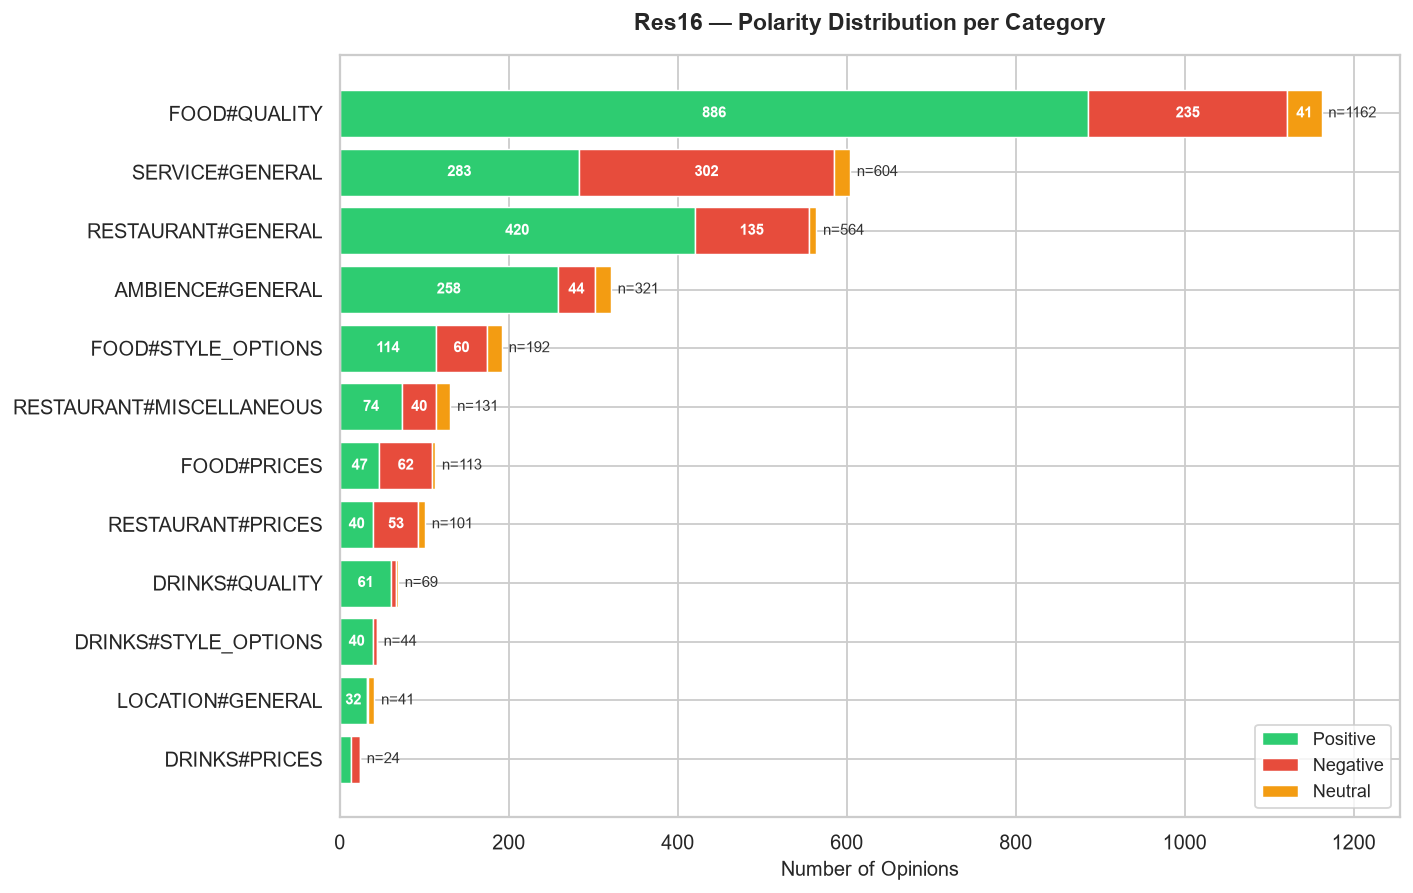

In [35]:
# ── Cell 9: Phân bố Polarity theo từng Category (stacked bar) ───────────────
cat_pol = (
    df.groupby(['category', 'polarity'])
      .size()
      .unstack(fill_value=0)
      .reindex(columns=['positive', 'negative', 'neutral'], fill_value=0)
)
# Sắp xếp theo tổng số opinions
cat_pol = cat_pol.loc[cat_pol.sum(axis=1).sort_values(ascending=True).index]

fig, ax = plt.subplots(figsize=(11, 7))
bottom = np.zeros(len(cat_pol))

for pol in ['positive', 'negative', 'neutral']:
    vals = cat_pol[pol].values
    bars = ax.barh(cat_pol.index, vals, left=bottom,
                   color=POLARITY_COLORS[pol], label=pol.capitalize(),
                   edgecolor='white', linewidth=0.8)
    # Annotate nếu đủ lớn
    for i, (bar, v) in enumerate(zip(bars, vals)):
        if v > 20:
            ax.text(bottom[i] + v / 2, i, str(v),
                    ha='center', va='center', fontsize=8.5,
                    color='white', fontweight='bold')
    bottom += vals

ax.set_xlabel('Number of Opinions', fontsize=11)
ax.set_title('Res16 — Polarity Distribution per Category', fontsize=13, fontweight='bold', pad=14)
ax.legend(loc='lower right', fontsize=10)
ax.set_xlim(0, bottom.max() * 1.08)
# Tổng số ở cuối mỗi bar
for i, total in enumerate(bottom):
    ax.text(total + 8, i, f'n={int(total)}', va='center', fontsize=8.5, color='#333')

plt.tight_layout()
plt.show()

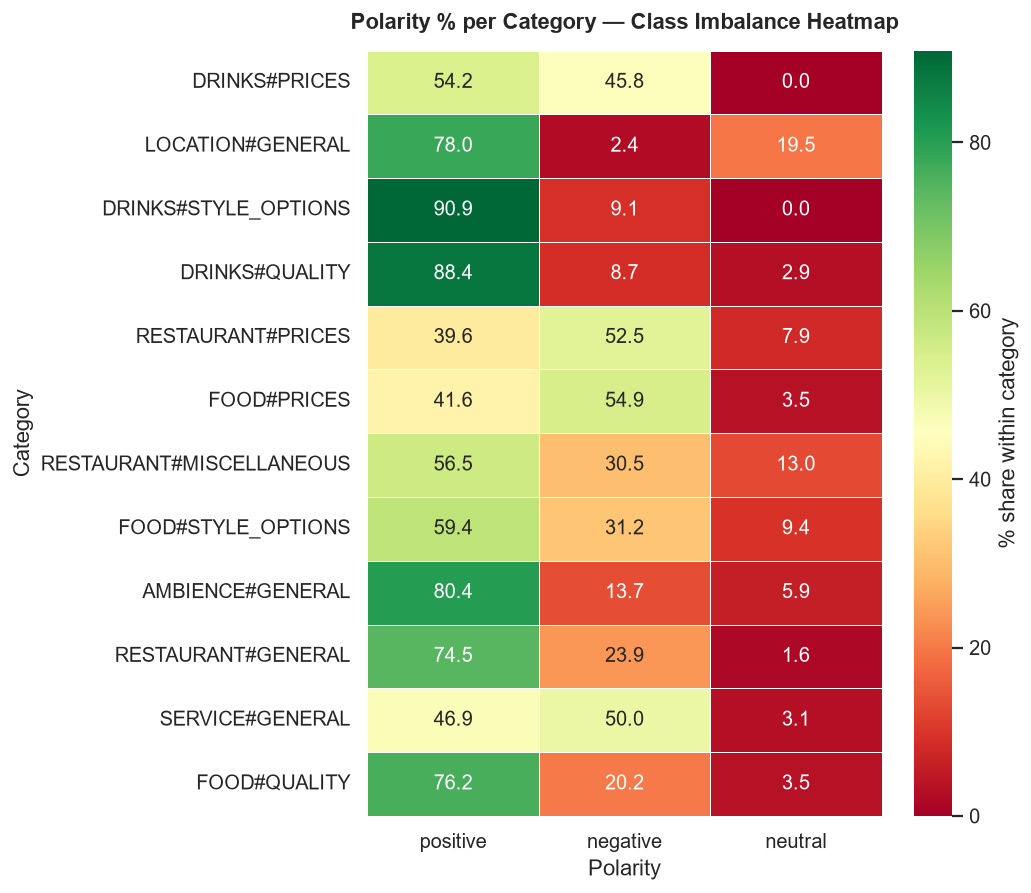

💡 Các ô màu đỏ đậm (gần 0%) là những category có class imbalance mạnh về phía class neutral (rất ít neutral).
   Ngược lại, positive chiếm đa số (màu xanh lá), trong khi neutral là class hiếm nhất ở hầu hết categories → cần chú ý khi evaluate model.


In [36]:
# ── Cell 10: Heatmap tỷ lệ % Polarity theo Category ─────────────────────────
cat_pol_pct = cat_pol.div(cat_pol.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(
    cat_pol_pct,
    annot=True, fmt='.1f', cmap='RdYlGn',
    linewidths=0.5, linecolor='white',
    cbar_kws={'label': '% share within category'},
    ax=ax
)
ax.set_title('Polarity % per Category — Class Imbalance Heatmap',
             fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Polarity'); ax.set_ylabel('Category')
plt.tight_layout()
plt.show()

print('💡 Các ô màu đỏ đậm (gần 0%) là những category có class imbalance mạnh về phía class neutral (rất ít neutral).')
print('   Ngược lại, positive chiếm đa số (màu xanh lá), trong khi neutral là class hiếm nhất ở hầu hết categories → cần chú ý khi evaluate model.')

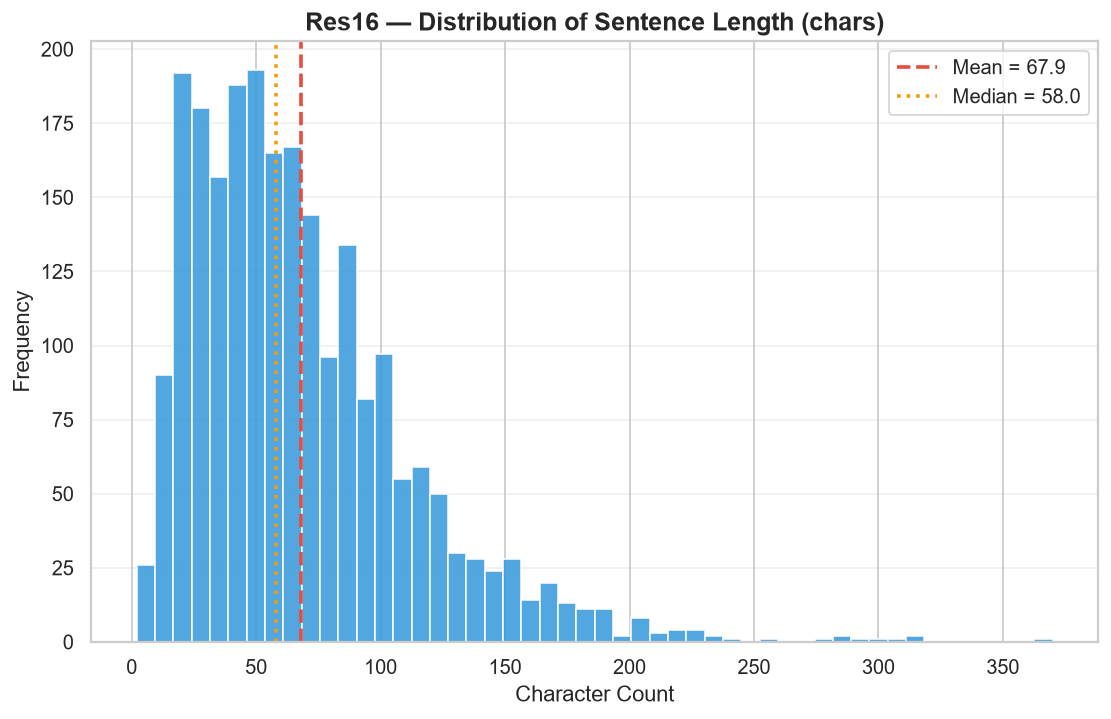

In [37]:
# ── Cell 11: Phân bố độ dài câu (Text Length) ───────────────────────────────
df_unique_texts = df.drop_duplicates(subset='text')[['text', 'text_len', 'split']].copy()

plt.figure(figsize=(10, 6))
plt.hist(df_unique_texts['text_len'], bins=50, color='#3498db', edgecolor='white', alpha=0.85)

mean_len = df_unique_texts['text_len'].mean()
median_len = df_unique_texts['text_len'].median()

plt.axvline(mean_len, color='#e74c3c', linestyle='--', linewidth=2, label=f'Mean = {mean_len:.1f}')
plt.axvline(median_len, color='#f39c12', linestyle=':', linewidth=2, label=f'Median = {median_len:.1f}')

plt.title('Res16 — Distribution of Sentence Length (chars)', fontsize=14, fontweight='bold')
plt.xlabel('Character Count')
plt.ylabel('Frequency')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

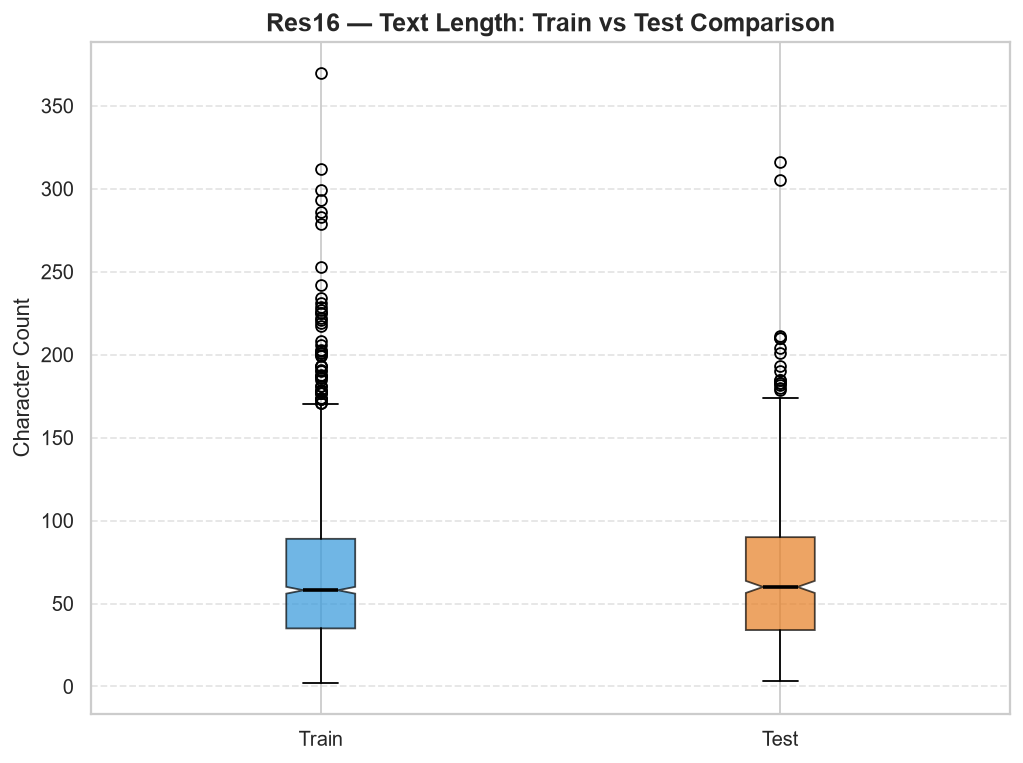

📏 Text length statistics (unique sentences):


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,585.0,67.9,45.1,3.0,34.0,60.0,90.0,316.0
train,1703.0,67.9,44.3,2.0,35.0,58.0,89.0,370.0


In [38]:
plt.figure(figsize=(8, 6))

train_lens = df_unique_texts[df_unique_texts['split']=='train']['text_len']
test_lens  = df_unique_texts[df_unique_texts['split']=='test']['text_len']

bp = plt.boxplot([train_lens, test_lens], tick_labels=['Train', 'Test'],
                 patch_artist=True, notch=True, # Thêm notch để so sánh median rõ hơn
                 medianprops=dict(color='black', linewidth=2))

colors = ['#3498db', '#e67e22']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

plt.title('Res16 — Text Length: Train vs Test Comparison', fontsize=14, fontweight='bold')
plt.ylabel('Character Count')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Hiển thị bảng thống kê mô tả để soi kỹ các con số (min, max, std)
print('📏 Text length statistics (unique sentences):')
display(df_unique_texts.groupby('split')['text_len'].describe().round(1))

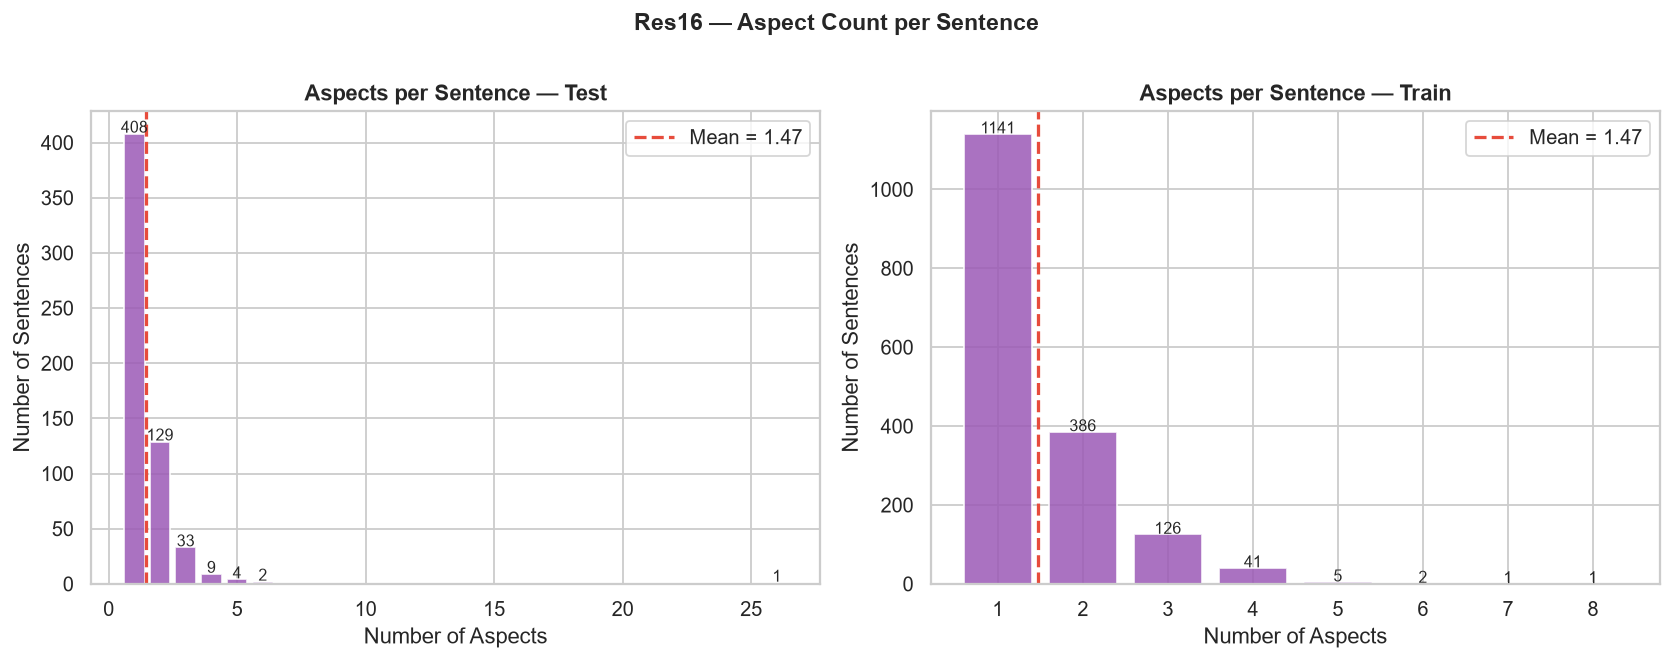

📐 Aspects per sentence statistics:


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,586.0,1.47,1.28,1.0,1.0,1.0,2.0,26.0
train,1703.0,1.47,0.80,1.0,1.0,1.0,2.0,8.0



🔍 Sentences with multiple aspects: 740 (32.3%)


In [39]:
# ── Cell 12: Số lượng Aspect trung bình per Sentence ─────────────────────────
aspects_per_sent = df.groupby(['split', 'text']).size().reset_index(name='n_aspects')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (split, grp) in zip(axes, aspects_per_sent.groupby('split')):
    vc = grp['n_aspects'].value_counts().sort_index()
    ax.bar(vc.index, vc.values,
           color='#9b59b6', edgecolor='white', alpha=0.85)
    ax.set_title(f'Aspects per Sentence — {split.capitalize()}', fontweight='bold')
    ax.set_xlabel('Number of Aspects'); ax.set_ylabel('Number of Sentences')
    avg = grp['n_aspects'].mean()
    ax.axvline(avg, color='#e74c3c', linestyle='--',
               linewidth=1.8, label=f'Mean = {avg:.2f}')
    ax.legend()
    for x, y in zip(vc.index, vc.values):
        ax.text(x, y + 1, str(y), ha='center', fontsize=9)

plt.suptitle('Res16 — Aspect Count per Sentence', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Summary stats
asp_stats = aspects_per_sent.groupby('split')['n_aspects'].describe().round(2)
print('📐 Aspects per sentence statistics:')
display(asp_stats)

multi = aspects_per_sent[aspects_per_sent['n_aspects'] > 1]
print(f'\n🔍 Sentences with multiple aspects: {len(multi):,} '
      f'({len(multi)/len(aspects_per_sent)*100:.1f}%)')

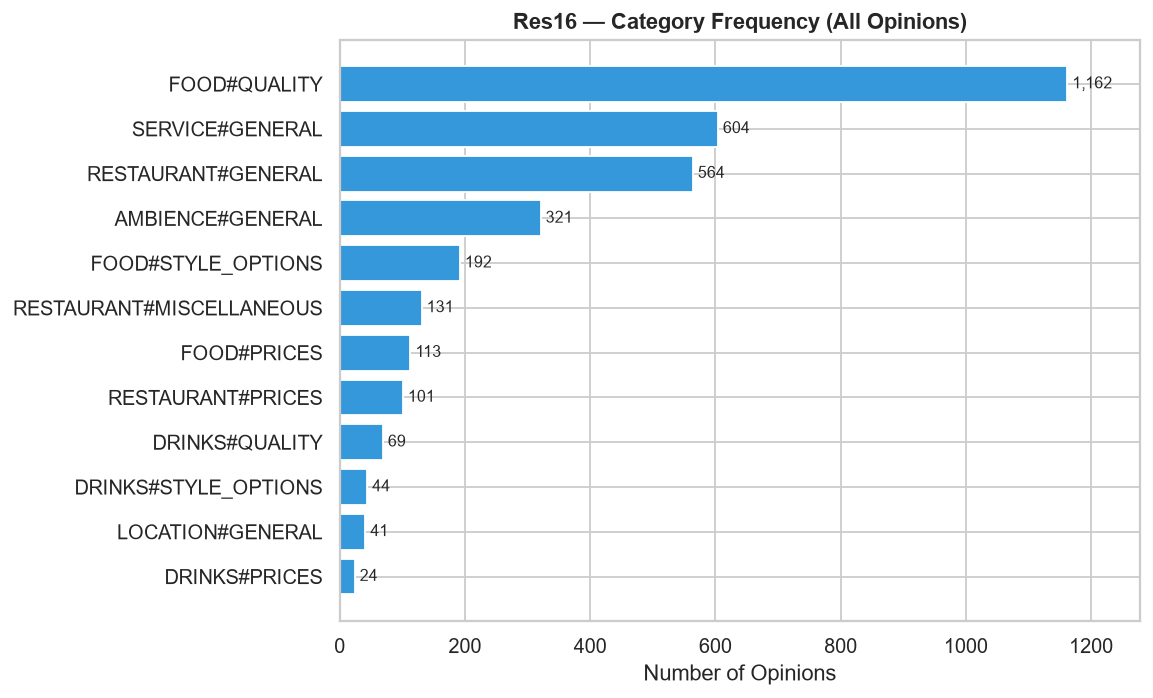

In [40]:
# ── Cell 13: Tần suất category (biểu đồ tĩnh, hiển thị được trên GitHub) ────
cat_counts = df['category'].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh(cat_counts.index, cat_counts.values, color='#3498db', edgecolor='white')
for b, v in zip(bars, cat_counts.values):
    ax.text(v + 8, b.get_y() + b.get_height()/2, f'{v:,}', va='center', fontsize=9)
ax.set_xlabel('Number of Opinions'); ax.set_title('Res16 — Category Frequency (All Opinions)', fontweight='bold')
ax.set_xlim(0, cat_counts.max() * 1.1)
plt.tight_layout(); plt.show()

In [41]:
# ── Cell 14: Sunburst — Cấu trúc phân cấp Entity → Attribute → Polarity ──────
hier = df.groupby(['entity', 'attribute', 'polarity']).size().reset_index(name='count')

fig = px.sunburst(
    hier, path=['entity', 'attribute', 'polarity'],
    values='count',
    color='polarity',
    color_discrete_map={
        'positive': '#2ecc71',
        'negative': '#e74c3c',
        'neutral' : '#f39c12',
        '(?)': '#bdc3c7'
    },
    title='Res16 — Label Hierarchy: Entity → Attribute → Polarity'
)
fig.update_layout(height=580)
fig.show()   # tương tác (plotly): không hiển thị trên GitHub; bản tĩnh tương đương ở Cell 9–10
print('💡 Click vào từng lớp để drill down vào cấu trúc phân cấp của nhãn.')

💡 Click vào từng lớp để drill down vào cấu trúc phân cấp của nhãn.


---
## 🔍 Bước 3 — Trích xuất Ví dụ & Minh hoạ Cơ chế Mapping

Phần này giúp team dễ hình dung *cụ thể* dữ liệu trông như thế nào,  
và minh hoạ luồng mapping logic của ABSA.

In [42]:
# ── Cell 15: Random examples per category ────────────────────────────────────
def show_random_examples(df: pd.DataFrame, n_per_cat: int = 2, seed: int = 42) -> pd.DataFrame:
    """
    Lấy n_per_cat ví dụ ngẫu nhiên cho mỗi (category, polarity) combo.
    Giúp team nhanh chóng nắm được dữ liệu trông như thế nào.
    """
    random.seed(seed)
    samples = []
    for (cat, pol), grp in df.groupby(['category', 'polarity']):
        n = min(n_per_cat, len(grp))
        chosen = grp.sample(n, random_state=seed)
        for _, row in chosen.iterrows():
            samples.append({
                'Category': cat,
                'Polarity': pol,
                'Example Sentence': row['text'][:120] + ('…' if len(row['text']) > 120 else '')
            })
    return pd.DataFrame(samples)

examples_df = show_random_examples(df, n_per_cat=1, seed=7)
print(f'📄 Random examples — {len(examples_df)} rows (1 per category×polarity combo):')
display(
    examples_df.style
    .map(lambda v: f'color: {POLARITY_COLORS.get(v,"black")}; font-weight:bold',
              subset=['Polarity'])
    .set_properties(**{'text-align': 'left', 'font-size': '11px'})
    .set_table_styles([{'selector':'th','props':[('text-align','left')]}])
)

📄 Random examples — 34 rows (1 per category×polarity combo):


,Category,Polarity,Example Sentence
0,AMBIENCE#GENERAL,negative,If you like your music blasted and the system isnt that great and if you want to pay at least 100 dollar bottle minimun …
1,AMBIENCE#GENERAL,neutral,"It may be a bit packed on weekends, but the vibe is good and it is the best French food you will find in the area."
2,AMBIENCE#GENERAL,positive,"good music, great food, speedy service affordable prices."
3,DRINKS#PRICES,negative,"They serve it in a tall, skinny hour-glass shaped glass to disguise the fact that you a getting a small juice at the pri…"
4,DRINKS#PRICES,positive,The food is great and they have a good selecion of wines at reasonable prices.
5,DRINKS#QUALITY,negative,"The bar drinks were Eh, ok to say the least."
6,DRINKS#QUALITY,neutral,Decent wine at reasonable prices.
7,DRINKS#QUALITY,positive,"We have since returned and also had a great experience, sampling more small plates and a variety of the beer ( cold and …"
8,DRINKS#STYLE_OPTIONS,negative,"Not much of a selection of bottled beer either, we went with Brahma."
9,DRINKS#STYLE_OPTIONS,positive,The wine list is also really nice.


In [43]:
# ── Cell 16: Hàm lookup ví dụ theo category cụ thể ───────────────────────────
def get_examples(df: pd.DataFrame, category: str, n: int = 3, seed: int = 0) -> None:
    """
    In ra n ví dụ cho một category cụ thể, phân loại theo polarity.
    Dùng để debug hoặc trình bày trong báo cáo.
    """
    subset = df[df['category'] == category]
    if subset.empty:
        print(f'Không tìm thấy category: {category}')
        return
    print(f'\n── Category: [{category}] ── ({len(subset)} opinions total) ──')
    for pol in ['positive', 'negative', 'neutral']:
        pool = subset[subset['polarity'] == pol]
        if pool.empty:
            continue
        sample = pool.sample(min(n, len(pool)), random_state=seed)
        icon = {'positive':'✅','negative':'❌','neutral':'➖'}[pol]
        print(f'\n  {icon} {pol.upper()} ({len(pool)} total):')
        for i, (_, row) in enumerate(sample.iterrows(), 1):
            print(f'    {i}. "{row["text"]}"')

# Ví dụ demo
get_examples(df, 'SERVICE#GENERAL', n=2)
get_examples(df, 'FOOD#QUALITY', n=2)
get_examples(df, 'AMBIENCE#GENERAL', n=2)


── Category: [SERVICE#GENERAL] ── (604 opinions total) ──

  ✅ POSITIVE (283 total):
    1. "I cannot imagine a friendlier staff working in a restaurant."
    2. "And it was quick which is very important."

  ❌ NEGATIVE (302 total):
    1. "I wish I could like this place more, and I wish someone would retrain the staff."
    2. "The service leaves much to be desired, from feeling like you are rushed the place your order, to being ignored the rest of the night."

  ➖ NEUTRAL (19 total):
    1. "The food arrived in about 15 minutes."
    2. "To sum it up: Service varies from good to mediorce, depending on which waiter you get; generally it is just average Ok."

── Category: [FOOD#QUALITY] ── (1162 opinions total) ──

  ✅ POSITIVE (886 total):
    1. "It melted in my little mouth and the perfect consistency-not too fishy, creamy, and slightly buttery."
    2. "I have lived in Japan for 7 years and the taste of the food and the feel of the restaurant is like being back in Japan."

  ❌ NEG

In [44]:
# ── Cell 17: Minh hoạ cơ chế ABSA Mapping Logic ─────────────────────────────
print('=' * 68)
print('   ABSA MAPPING LOGIC — ILLUSTRATION')
print('   (Các câu dưới đây do nhóm TỰ SOẠN để minh hoạ, KHÔNG lấy từ dữ liệu Res16.)')
print('=' * 68)

mapping_examples = [
    {
        'sentence': 'The receptionist provided good service.',
        'aspect_term': 'service',
        'category': 'SERVICE#GENERAL',
        'polarity': 'positive',
        'reasoning': '"provided good" → positive sentiment về SERVICE'
    },
    {
        'sentence': 'The receptionist provided terrible service.',
        'aspect_term': 'service',
        'category': 'SERVICE#GENERAL',
        'polarity': 'negative',
        'reasoning': '"provided terrible" → negative sentiment về SERVICE'
    },
    {
        'sentence': 'The duck confit is always amazing.',
        'aspect_term': 'duck confit',
        'category': 'FOOD#QUALITY',
        'polarity': 'positive',
        'reasoning': '"always amazing" → positive sentiment về FOOD quality'
    },
    {
        'sentence': 'The portions were tiny and overpriced.',
        'aspect_term': 'portions',
        'category': 'FOOD#STYLE_OPTIONS',
        'polarity': 'negative',
        'reasoning': '"tiny" → negative sentiment về FOOD style/options'
    },
    {
        'sentence': 'The atmosphere was okay, nothing special.',
        'aspect_term': 'atmosphere',
        'category': 'AMBIENCE#GENERAL',
        'polarity': 'neutral',
        'reasoning': '"okay, nothing special" → neutral sentiment về AMBIENCE'
    },
]

for i, ex in enumerate(mapping_examples, 1):
    icon = {'positive':'✅','negative':'❌','neutral':'➖'}[ex['polarity']]
    print(f'\nExample {i}:')
    print(f'  📝 Sentence    : "{ex["sentence"]}"')
    print(f'  🎯 Aspect Term : [{ex["aspect_term"]}]')
    print(f'  🏷️  Category   : {ex["category"]}')
    print(f'  {icon} Polarity   : {ex["polarity"].upper()}')
    print(f'  💡 Reasoning   : {ex["reasoning"]}')

print('\n' + '=' * 68)
print('KEY INSIGHT: Cùng 1 cấu trúc câu, thay đổi opinion word →')
print('             category giữ nguyên, chỉ có polarity thay đổi.')
print('             Model ABSA cần học được sự khác biệt này.')
print('=' * 68)

   ABSA MAPPING LOGIC — ILLUSTRATION
   (Các câu dưới đây do nhóm TỰ SOẠN để minh hoạ, KHÔNG lấy từ dữ liệu Res16.)

Example 1:
  📝 Sentence    : "The receptionist provided good service."
  🎯 Aspect Term : [service]
  🏷️  Category   : SERVICE#GENERAL
  ✅ Polarity   : POSITIVE
  💡 Reasoning   : "provided good" → positive sentiment về SERVICE

Example 2:
  📝 Sentence    : "The receptionist provided terrible service."
  🎯 Aspect Term : [service]
  🏷️  Category   : SERVICE#GENERAL
  ❌ Polarity   : NEGATIVE
  💡 Reasoning   : "provided terrible" → negative sentiment về SERVICE

Example 3:
  📝 Sentence    : "The duck confit is always amazing."
  🎯 Aspect Term : [duck confit]
  🏷️  Category   : FOOD#QUALITY
  ✅ Polarity   : POSITIVE
  💡 Reasoning   : "always amazing" → positive sentiment về FOOD quality

Example 4:
  📝 Sentence    : "The portions were tiny and overpriced."
  🎯 Aspect Term : [portions]
  🏷️  Category   : FOOD#STYLE_OPTIONS
  ❌ Polarity   : NEGATIVE
  💡 Reasoning   : "tiny" → ne

In [45]:
# ── Cell 18: Minh hoạ Multi-aspect sentence ──────────────────────────────────
print('MULTI-ASPECT SENTENCE EXAMPLE')
print('=' * 68)
print('Một câu có thể chứa nhiều aspect opinions cùng lúc:')
print()

# Tìm câu thực sự có ≥3 aspects trong dataset
multi = df.groupby('text').filter(lambda x: len(x) >= 3)
if not multi.empty:
    sample_text = multi.groupby('text').size().idxmax()
    sample_opinions = df[df['text'] == sample_text][['category', 'polarity']].values
    print(f'📝 Sentence: "{sample_text}"')
    print(f'\n   Contains {len(sample_opinions)} aspect opinions:')
    for j, (cat, pol) in enumerate(sample_opinions, 1):
        icon = {'positive':'✅','negative':'❌','neutral':'➖'}.get(pol, '?')
        print(f'   Aspect {j}: [{cat}] → {icon} {pol.upper()}')
else:
    print('(Không tìm thấy ví dụ phù hợp trong dataset.)')

print()
print('💡 Đây chính là thách thức của ABSA: model phải phân biệt được')
print('   từng aspect riêng biệt trong cùng một câu.')

MULTI-ASPECT SENTENCE EXAMPLE
Một câu có thể chứa nhiều aspect opinions cùng lúc:

📝 Sentence: "Your a sushi fan, you love expertly cut fish, great sake, a killer SOHO location, and of course: Salmon, Tuna, Fluke, Yellow Tail, Cod, Mackeral, Jellyfish, Sea Urchin, Shrimp, Lobster, Sea Bream, Trout, Milk Fish, Blue Fin Tuna, Eel, Crab, Sardine, Monk Fish, Roe, Scallop, Oysters, and a varity of Toro."

   Contains 26 aspect opinions:
   Aspect 1: [FOOD#QUALITY] → ✅ POSITIVE
   Aspect 2: [FOOD#STYLE_OPTIONS] → ✅ POSITIVE
   Aspect 3: [DRINKS#QUALITY] → ✅ POSITIVE
   Aspect 4: [LOCATION#GENERAL] → ✅ POSITIVE
   Aspect 5: [FOOD#QUALITY] → ✅ POSITIVE
   Aspect 6: [FOOD#QUALITY] → ✅ POSITIVE
   Aspect 7: [FOOD#QUALITY] → ✅ POSITIVE
   Aspect 8: [FOOD#QUALITY] → ✅ POSITIVE
   Aspect 9: [FOOD#QUALITY] → ✅ POSITIVE
   Aspect 10: [FOOD#QUALITY] → ✅ POSITIVE
   Aspect 11: [FOOD#QUALITY] → ✅ POSITIVE
   Aspect 12: [FOOD#QUALITY] → ✅ POSITIVE
   Aspect 13: [FOOD#QUALITY] → ✅ POSITIVE
   Aspect 14: [

---
## ➕ Bước 2b — Bổ sung: những con số mà bước huấn luyện thực sự cần

Các mục dưới đây trả lời những câu hỏi mà notebook huấn luyện phụ thuộc vào nhưng bản EDA cũ chưa tính:
phân bố nhãn **giữa train và test** (có lệch không?), **độ dài tính theo token** (có cần `MAX_LEN=256` không?),
tỉ lệ **target ngầm định** và mức độ **trùng lặp** giữa train và test.

In [46]:
# ── Cell 14b: Phân bố polarity train vs test ───────────────────────────────
tab = pd.crosstab(df['split'], df['polarity'])[['positive', 'negative', 'neutral']]
tab_pct = (tab.div(tab.sum(axis=1), axis=0) * 100).round(1)
display(pd.concat({'số opinion': tab, '% trong split': tab_pct}, axis=1))
print('→ Test lệch nhẹ so với train: ít negative hơn (≈24% so với ≈30%), nhiều positive hơn. Test chỉ có 44 mẫu neutral nên F1 lớp neutral rất nhiễu (1 câu ≈ 2,3% recall).')

số opinion                  % trong split                 
polarity   positive negative neutral      positive negative neutral
split                                                              
test            611      204      44          71.1     23.7     5.1
train          1657      749     101          66.1     29.9     4.0

→ Test lệch nhẹ so với train: ít negative hơn (≈24% so với ≈30%), nhiều positive hơn. Test chỉ có 44 mẫu neutral nên F1 lớp neutral rất nhiễu (1 câu ≈ 2,3% recall).


In [47]:
# ── Cell 14c: Độ dài theo số token (xấp xỉ) và so với MAX_LEN ───────────────
# Không có tokenizer BERT offline → đếm token bằng regex (từ + dấu câu). WordPiece cho số token ≥ con số này
# (thường nhiều hơn ~10–30%), nên ta cộng dư để ước lượng cận trên.
tok = lambda s: len(re.findall(r"\w+|[^\w\s]", s))
u = df.drop_duplicates('text')[['text']].copy()
u['n_tok'] = u['text'].map(tok)
u['n_tok_upper'] = (u['n_tok'] * 1.5).round() + 3 + 4   # ×1.5 cho wordpiece, +3 [CLS]/[SEP]/[SEP], +4 token của aspect
print(u['n_tok'].describe().round(1).to_string())
print(f"\nCâu dài nhất: {u['n_tok'].max()} token (regex) → cận trên ≈ {int(u['n_tok_upper'].max())} token BERT (gồm aspect)")
for L in (64, 96, 128, 256):
    print(f'  Tỉ lệ câu có cận trên token ≤ {L:>3}: {(u["n_tok_upper"] <= L).mean()*100:5.1f}%')
print('→ Hầu hết câu ngắn hơn rất nhiều so với MAX_LEN=256 của notebook 03; phần còn lại là padding.')

count    2288.0
mean       15.0
std         9.7
min         1.0
25%         8.0
50%        13.0
75%        19.0
max        84.0

Câu dài nhất: 84 token (regex) → cận trên ≈ 133 token BERT (gồm aspect)
  Tỉ lệ câu có cận trên token ≤  64:  97.2%
  Tỉ lệ câu có cận trên token ≤  96:  99.7%
  Tỉ lệ câu có cận trên token ≤ 128: 100.0%
  Tỉ lệ câu có cận trên token ≤ 256: 100.0%
→ Hầu hết câu ngắn hơn rất nhiều so với MAX_LEN=256 của notebook 03; phần còn lại là padding.


In [48]:
# ── Cell 14d: Target ngầm định (NULL) và trùng lặp train/test ───────────────
df['implicit'] = df['target'].eq('NULL')
print('Tỉ lệ opinion có target ngầm định (target = NULL):')
display((df.groupby('split')['implicit'].agg(['mean', 'sum', 'size']).rename(columns={'mean':'tỉ lệ','sum':'số NULL','size':'tổng'})).round(3))
print('Polarity theo loại target:')
display(pd.crosstab(df['implicit'], df['polarity'], normalize='index').round(3))
overlap = set(df_train['text']) & set(df_test['text'])
print(f'\nCâu xuất hiện ở cả train và test: {len(overlap)}')
print(f"Số câu có nhãn / số review — train: {df_train.sid.nunique()} / {df_train.rid.nunique()}, test: {df_test.sid.nunique()} / {df_test.rid.nunique()}")
print('→ Một review có nhiều câu cùng chủ đề; vì vậy tách validation phải tách THEO REVIEW (xem src/absa_common.py).')

Tỉ lệ opinion có target ngầm định (target = NULL):


,tỉ lệ,số NULL,tổng
split,,,
test,0.243,209,859
train,0.250,627,2507


Polarity theo loại target:


polarity,negative,neutral,positive
implicit,,,
False,0.247,0.041,0.712
True,0.394,0.049,0.557



Câu xuất hiện ở cả train và test: 1
Số câu có nhãn / số review — train: 1708 / 349, test: 587 / 90
→ Một review có nhiều câu cùng chủ đề; vì vậy tách validation phải tách THEO REVIEW (xem src/absa_common.py).


In [49]:
# ── Cell 14e: Kiểm chứng ký tự đặc biệt / emoji / URL (câu duy nhất) ────────
EMOJI = re.compile('[\U0001F300-\U0001FAFF\u2600-\u27BF]')
u = df.drop_duplicates('text')['text']
stat = {
    'có emoji': u.map(lambda s: bool(EMOJI.search(s))).mean(),
    'có URL': u.str.contains(r'http|www\.').mean(),
    'có ít nhất 1 dấu câu / ký tự không phải chữ-số': u.map(lambda s: bool(re.search(r'[^\w\s]', s))).mean(),
    'có ký tự lạ (ngoài chữ, số, . , ! ? \' -)': u.map(lambda s: bool(re.search(r"[^\w\s\.,!?'\-]", s))).mean(),
}
for k, v in stat.items(): print(f'{k:<55}: {v*100:5.1f}%')
print('→ Res16 là văn bản tiếng Anh sạch: không có emoji hay URL. Vì vậy các bước demojize / bỏ URL trong tiền xử lý hầu như không có tác dụng với bộ này.')

có emoji                                               :   0.0%
có URL                                                 :   0.0%
có ít nhất 1 dấu câu / ký tự không phải chữ-số         :  95.9%
có ký tự lạ (ngoài chữ, số, . , ! ? ' -)               :  13.2%
→ Res16 là văn bản tiếng Anh sạch: không có emoji hay URL. Vì vậy các bước demojize / bỏ URL trong tiền xử lý hầu như không có tác dụng với bộ này.


---
## 📋 Tổng kết — Data Quality Summary

In [50]:
# ── Cell 19: Comprehensive Summary Table ─────────────────────────────────────
print('=' * 60)
print('   RES16 DATASET — EDA SUMMARY REPORT')
print('=' * 60)

print(f'\n📦 DATASET OVERVIEW')
print(f'   Total opinions (after flatten) : {len(df):,}')
print(f'   Training opinions              : {len(df_train):,}')
print(f'   Test opinions                  : {len(df_test):,}')
print(f'   Unique sentences               : {df["text"].nunique():,}')

print(f'\n🏷️  LABEL SPACE')
print(f'   Unique entities (E)            : {df["entity"].nunique()}')
print(f'   Unique attributes (A)          : {df["attribute"].nunique()}')
print(f'   Unique categories (E#A)        : {df["category"].nunique()}')
print(f'   Unique polarities              : {df["polarity"].nunique()}')
print(f'   Max theoretical label combos   : {df["category"].nunique() * df["polarity"].nunique()}')
print(f'   Actual observed combos         : {df.groupby(["category","polarity"]).ngroups}')

pol_dist = df['polarity'].value_counts(normalize=True) * 100
print(f'\n📊 POLARITY DISTRIBUTION')
for pol in ['positive', 'negative', 'neutral']:
    count = df['polarity'].value_counts()[pol]
    pct   = pol_dist[pol]
    print(f'   {pol.capitalize():<12}: {count:,} ({pct:.1f}%)')

asp_avg = df.groupby('text').size().mean()
print(f'\n📐 TEXT & ASPECT STATS')
print(f'   Mean sentence length (chars)   : {df_unique_texts["text_len"].mean():.1f}')
print(f'   Median sentence length (chars) : {df_unique_texts["text_len"].median():.1f}')
print(f'   Mean aspects per sentence      : {asp_avg:.2f}')
multi_asp_pct = (df.groupby('text').size() > 1).mean() * 100
print(f'   Sentences with >1 aspect       : {multi_asp_pct:.1f}%')

print(f'\n✅ DATA QUALITY')
print(f'   Missing category values        : {df["category"].isna().sum()}')
print(f'   Missing polarity values        : {df["polarity"].isna().sum()}')
print(f'   Missing text values            : {df["text"].isna().sum()}')

print('\n' + '=' * 60)
print('   Dataset sẵn sàng cho bước huấn luyện model!')
print('=' * 60)

   RES16 DATASET — EDA SUMMARY REPORT

📦 DATASET OVERVIEW
   Total opinions (after flatten) : 3,366
   Training opinions              : 2,507
   Test opinions                  : 859
   Unique sentences               : 2,288

🏷️  LABEL SPACE
   Unique entities (E)            : 6
   Unique attributes (A)          : 5
   Unique categories (E#A)        : 12


   Unique polarities              : 3
   Max theoretical label combos   : 36
   Actual observed combos         : 34

📊 POLARITY DISTRIBUTION
   Positive    : 2,268 (67.4%)
   Negative    : 953 (28.3%)
   Neutral     : 145 (4.3%)

📐 TEXT & ASPECT STATS
   Mean sentence length (chars)   : 67.9
   Median sentence length (chars) : 58.0
   Mean aspects per sentence      : 1.47
   Sentences with >1 aspect       : 32.4%

✅ DATA QUALITY
   Missing category values        : 0
   Missing polarity values        : 0
   Missing text values            : 0

   Dataset sẵn sàng cho bước huấn luyện model!


In [51]:
# ── Cell 20 (Optional): Export flat DataFrame để dùng lại ────────────────────
# df.to_csv('res16_flat_combined.csv', index=False)
# print('✅ Exported to res16_flat_combined.csv')
print('💾 Để export: bỏ comment dòng trên và chạy lại cell này.')
print(f'   Flat DataFrame sẵn có trong biến `df` với shape {df.shape}')

💾 Để export: bỏ comment dòng trên và chạy lại cell này.
   Flat DataFrame sẵn có trong biến `df` với shape (3366, 11)
